In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../src")))

from autoencoder import SINDyConvAE
from training import train_sindy_convae, save_model_and_params
from sindy_utils import library_size

[INFO] Global seed set to 42 (PyTorch, NumPy, Random)


In [ ]:
def generate_spiral_dataset_fixed_dt(n_samples=2000, img_size=32, dt=0.05):
    """
    Generate a dataset of spiral motion with dt constant. 
    Aumentare n_samples aumenta la durata totale della simulazione.
    """
    # Griglia spaziale
    x_grid = np.linspace(-1, 1, img_size)
    y_grid = np.linspace(-1, 1, img_size)
    X_mesh, Y_mesh = np.meshgrid(x_grid, y_grid)
    
    sigma = 0.1
    
    # Tempo: t cresce linearmente con dt costante
    # t.shape = (n_samples,)
    t = np.arange(n_samples) * dt
    
    # Traiettoria latente z(t)
    z1 = 0.5 * np.cos(t)
    z2 = 0.5 * np.sin(t)
    
    # Derivate analitiche dz/dt (rispetto al tempo reale t)
    dz1 = -0.5 * np.sin(t)
    dz2 =  0.5 * np.cos(t)
    
    # Vettorializzazione per generare tutte le immagini contemporaneamente
    # Prepariamo le mesh per il broadcasting: (1, img_size, img_size)
    # Prepariamo z per il broadcasting: (n_samples, 1, 1)
    diff_x = X_mesh[None, :, :] - z1[:, None, None]
    diff_y = Y_mesh[None, :, :] - z2[:, None, None]
    dist_sq = diff_x**2 + diff_y**2
    
    # Generazione stack immagini X: (n_samples, img_size, img_size)
    img_stack = np.exp(-dist_sq / (2 * sigma**2))
    
    # Calcolo dX/dt (Chain Rule vettorializzata)
    # du_dt è la derivata dell'esponente
    du_dt = -2 * diff_x * dz1[:, None, None] - 2 * diff_y * dz2[:, None, None]
    dimg_stack = img_stack * (-1 / (2 * sigma**2)) * du_dt
    
    # Conversione in Tensor PyTorch [N, H, W, C]
    X_tensor = torch.FloatTensor(img_stack).unsqueeze(-1)
    dX_tensor = torch.FloatTensor(dimg_stack).unsqueeze(-1)
    
    # Split Train/Val (80/20) - Manteniamo l'ordine temporale per la validazione
    split = int(n_samples * 0.8)
    train_data = (X_tensor[:split], dX_tensor[:split])
    val_data = (X_tensor[split:], dX_tensor[split:])
    
    return train_data, val_data

# --- ESECUZIONE ---

# Parametri fissati
DT_COSTANTE = 0.05
N_SAMPLES = 2000 # 2000 * 0.05 = 100 secondi di simulazione

(train_x, train_dx), (val_x, val_dx) = generate_spiral_dataset_fixed_dt(
    n_samples=N_SAMPLES, 
    img_size=32, 
    dt=DT_COSTANTE
)

# Loader: shuffle=True solo per il train per rompere la correlazione temporale nel gradiente,
# ma i valori di dX rimangono corretti rispetto al loro dt originale.
train_loader = DataLoader(TensorDataset(train_x, train_dx), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(val_x, val_dx), batch_size=32, shuffle=False)

print(f"Dataset generato: {len(train_x)} campioni di train, {len(val_x)} di validazione.")
print(f"Tempo totale simulato: {N_SAMPLES * DT_COSTANTE} secondi.")

Dataset generato: 1600 campioni di train, 400 di validazione.
Tempo totale simulato: 100.0 secondi.


In [3]:
# Problem parameters
params={}

# CAE structure
params['input_shape'] = (32, 32, 1)
params['filter_widths'] = [8, 16, 32]

# SINDy latent library
params['latent_dim'] = 2
params['poly_order'] = 3
params['include_sine'] = True
params['library_dim'] = library_size(params['latent_dim'], params['poly_order'], params['include_sine'])

# Loss penalties
params['loss_weights'] = { 
   'decoder': 1.0,            
   'sindy_x': 1e-3,
   'sindy_z': 1e-3,
   'sindy_reg': 1e-5
   }

# Thresholding
params['sequential_thresholding'] = True
params['threshold_frequency'] = 100
params['coefficient_threshold'] = 0.1

# Training
params['activation'] = 'tanh'
params['learning_rate'] = 1e-3
params['batch_size'] = 32
params['print_frequency'] = 20

params['max_epochs'] = 2001
params['refinement_epochs'] = 201


In [ ]:
# Model
model = SINDyConvAE(params)

# Train of the model
history = train_sindy_convae(model, train_loader, val_loader, params)

# Save
save_model_and_params(model, params, folder_path="./saved_models", model_name="test")


[REFINE] Epoch   40
  Train Loss: 2.3919e-06 ( Dec: 2.16e-06 | dX: 1.12e-04 | dZ: 1.16e-04 )
  Valid Loss: 1.5667e-06 ( Dec: 1.38e-06 | dX: 1.01e-04 | dZ: 8.26e-05 )
  >> RATIO: Decoder: 0.0002 | SINDy: 0.0011
[REFINE] Epoch   60
  Train Loss: 3.3129e-06 ( Dec: 3.06e-06 | dX: 1.18e-04 | dZ: 1.38e-04 )
  Valid Loss: 3.2127e-06 ( Dec: 2.79e-06 | dX: 1.29e-04 | dZ: 2.90e-04 )
  >> RATIO: Decoder: 0.0004 | SINDy: 0.0014
[REFINE] Epoch   80
  Train Loss: 2.3573e-06 ( Dec: 2.14e-06 | dX: 1.09e-04 | dZ: 1.08e-04 )
  Valid Loss: 4.0378e-06 ( Dec: 3.72e-06 | dX: 1.25e-04 | dZ: 1.90e-04 )
  >> RATIO: Decoder: 0.0005 | SINDy: 0.0014
[REFINE] Epoch  100
  Train Loss: 1.0631e-06 ( Dec: 9.51e-07 | dX: 8.92e-05 | dZ: 2.25e-05 )
  Valid Loss: 1.2037e-06 ( Dec: 1.09e-06 | dX: 9.25e-05 | dZ: 2.61e-05 )
  >> RATIO: Decoder: 0.0001 | SINDy: 0.0010
[REFINE] Epoch  120
  Train Loss: 2.2163e-06 ( Dec: 2.02e-06 | dX: 1.02e-04 | dZ: 9.02e-05 )
  Valid Loss: 1.6317e-06 ( Dec: 1.50e-06 | dX: 9.90e-05 | dZ: 2.80e

In [ ]:
# Analisi dei risultati finali
with torch.no_grad():
    # .detach() rimuove il tensore dal grafo dei gradienti
    final_xi = (model.sindy_coeffs * model.sindy_mask).detach().cpu().numpy()

print("Xi final:")
print(np.round(final_xi, 4)) 

active_mask = np.abs(final_xi) > 0
print(f"Active coefficients: {np.sum(active_mask)}")

Xi final:
[[ 1.5407 -0.    ]
 [-0.     -0.    ]
 [-0.     -0.    ]
 [ 0.2345 -0.    ]
 [-0.     -0.    ]
 [-0.3531 -0.    ]
 [-0.      0.1548]
 [-0.2225  0.    ]
 [-0.      0.    ]
 [ 0.      0.    ]
 [-0.     -0.    ]
 [ 0.     -0.    ]]
Active coefficients: 5


# Inference

In [ ]:
from training import load_model_and_params
# Sostituisci './saved_models' con il percorso dove hai salvato i file .pth e .pkl
# 'test_torch' è il nome che hai usato nel salvataggio precedente
model, params = load_model_and_params('./saved_models', model_name="test")

print("[INFO] Modello caricato con successo!")
print(f"Soglia coefficienti originale: {params['coefficient_threshold']}")

[INFO] Modello caricato con successo!
Soglia coefficienti originale: 0.1


In [ ]:
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def test_rom_inference(model, n_test_samples=500, img_size=32, dt=0.05):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    # --- 1. GENERA DATASET DI TEST ---
    # Usiamo la funzione corretta con dt fissato
    # (Supponendo che la funzione restituisca (X, dX), prendiamo solo il primo tuple)
    test_data, _ = generate_spiral_dataset_fixed_dt(n_samples=n_test_samples, img_size=img_size, dt=dt)
    test_x, _ = test_data 
    
    # Prepariamo il loader per la proiezione
    test_loader = DataLoader(TensorDataset(test_x, test_x), batch_size=32, shuffle=False)

    # --- 2. PROIEZIONE LATENTE (Ground Truth dell'Encoder) ---
    all_z_real = []
    with torch.no_grad():
        for x, _ in test_loader:
            z = model.encode(x.to(device))
            all_z_real.append(z.cpu().numpy())
    all_z_real = np.concatenate(all_z_real, axis=0)

    # --- 3. EVOLUZIONE SINDy (Integrazione Numerica) ---
    def sindy_dynamics(z, t):
        z_tensor = torch.tensor(z.reshape(1, -1), dtype=torch.float32).to(device)
        with torch.no_grad():
            theta = model.construct_sindy_library(z_tensor)
            dzdt = torch.matmul(theta, model.sindy_coeffs * model.sindy_mask)
        return dzdt.cpu().numpy().flatten()

    # Definiamo il tempo basandoci sul dt fisso
    t_sim = np.arange(n_test_samples) * dt
    z0 = all_z_real[0] # Partiamo dal primo punto proiettato
    
    # Integrazione
    z_simulated = odeint(sindy_dynamics, z0, t_sim)

    # --- 4. PLOT ---
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))

    # Latente Reale
    ax[0].plot(all_z_real[:, 0], all_z_real[:, 1], 'b-', label='Target (Encoder)')
    ax[0].scatter(all_z_real[0, 0], all_z_real[0, 1], color='green', s=100, zorder=5, label='Start')
    ax[0].set_title(f"Spazio Latente (dt={dt})")
    ax[0].legend()
    ax[0].grid(True)

    # Confronto Evoluzione
    ax[1].plot(all_z_real[:, 0], all_z_real[:, 1], 'b-', alpha=0.3, label='Reale')
    ax[1].plot(z_simulated[:, 0], z_simulated[:, 1], 'r--', label='SINDy Evolution')
    ax[1].set_title("Validazione ROM: Traiettoria Simulata")
    ax[1].legend()
    ax[1].grid(True)

    plt.show()

    return all_z_real, z_simulated

# Esecuzione
# z_real, z_sim = test_rom_inference(model, n_test_samples=500, dt=0.05)

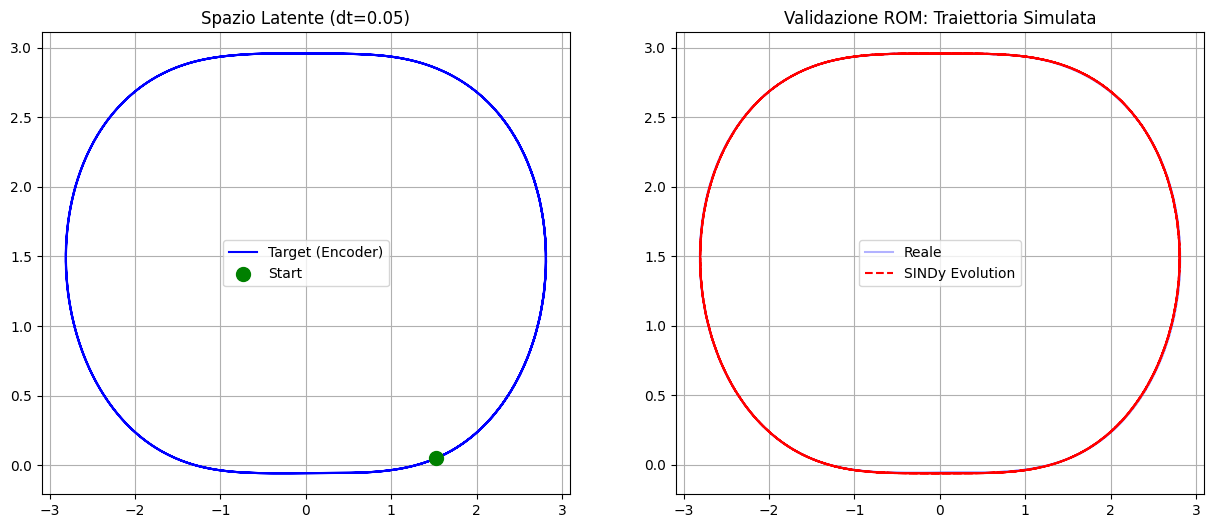

In [9]:
# Esecuzione
z_real, z_sim = test_rom_inference(model, n_test_samples=500, dt=0.05)

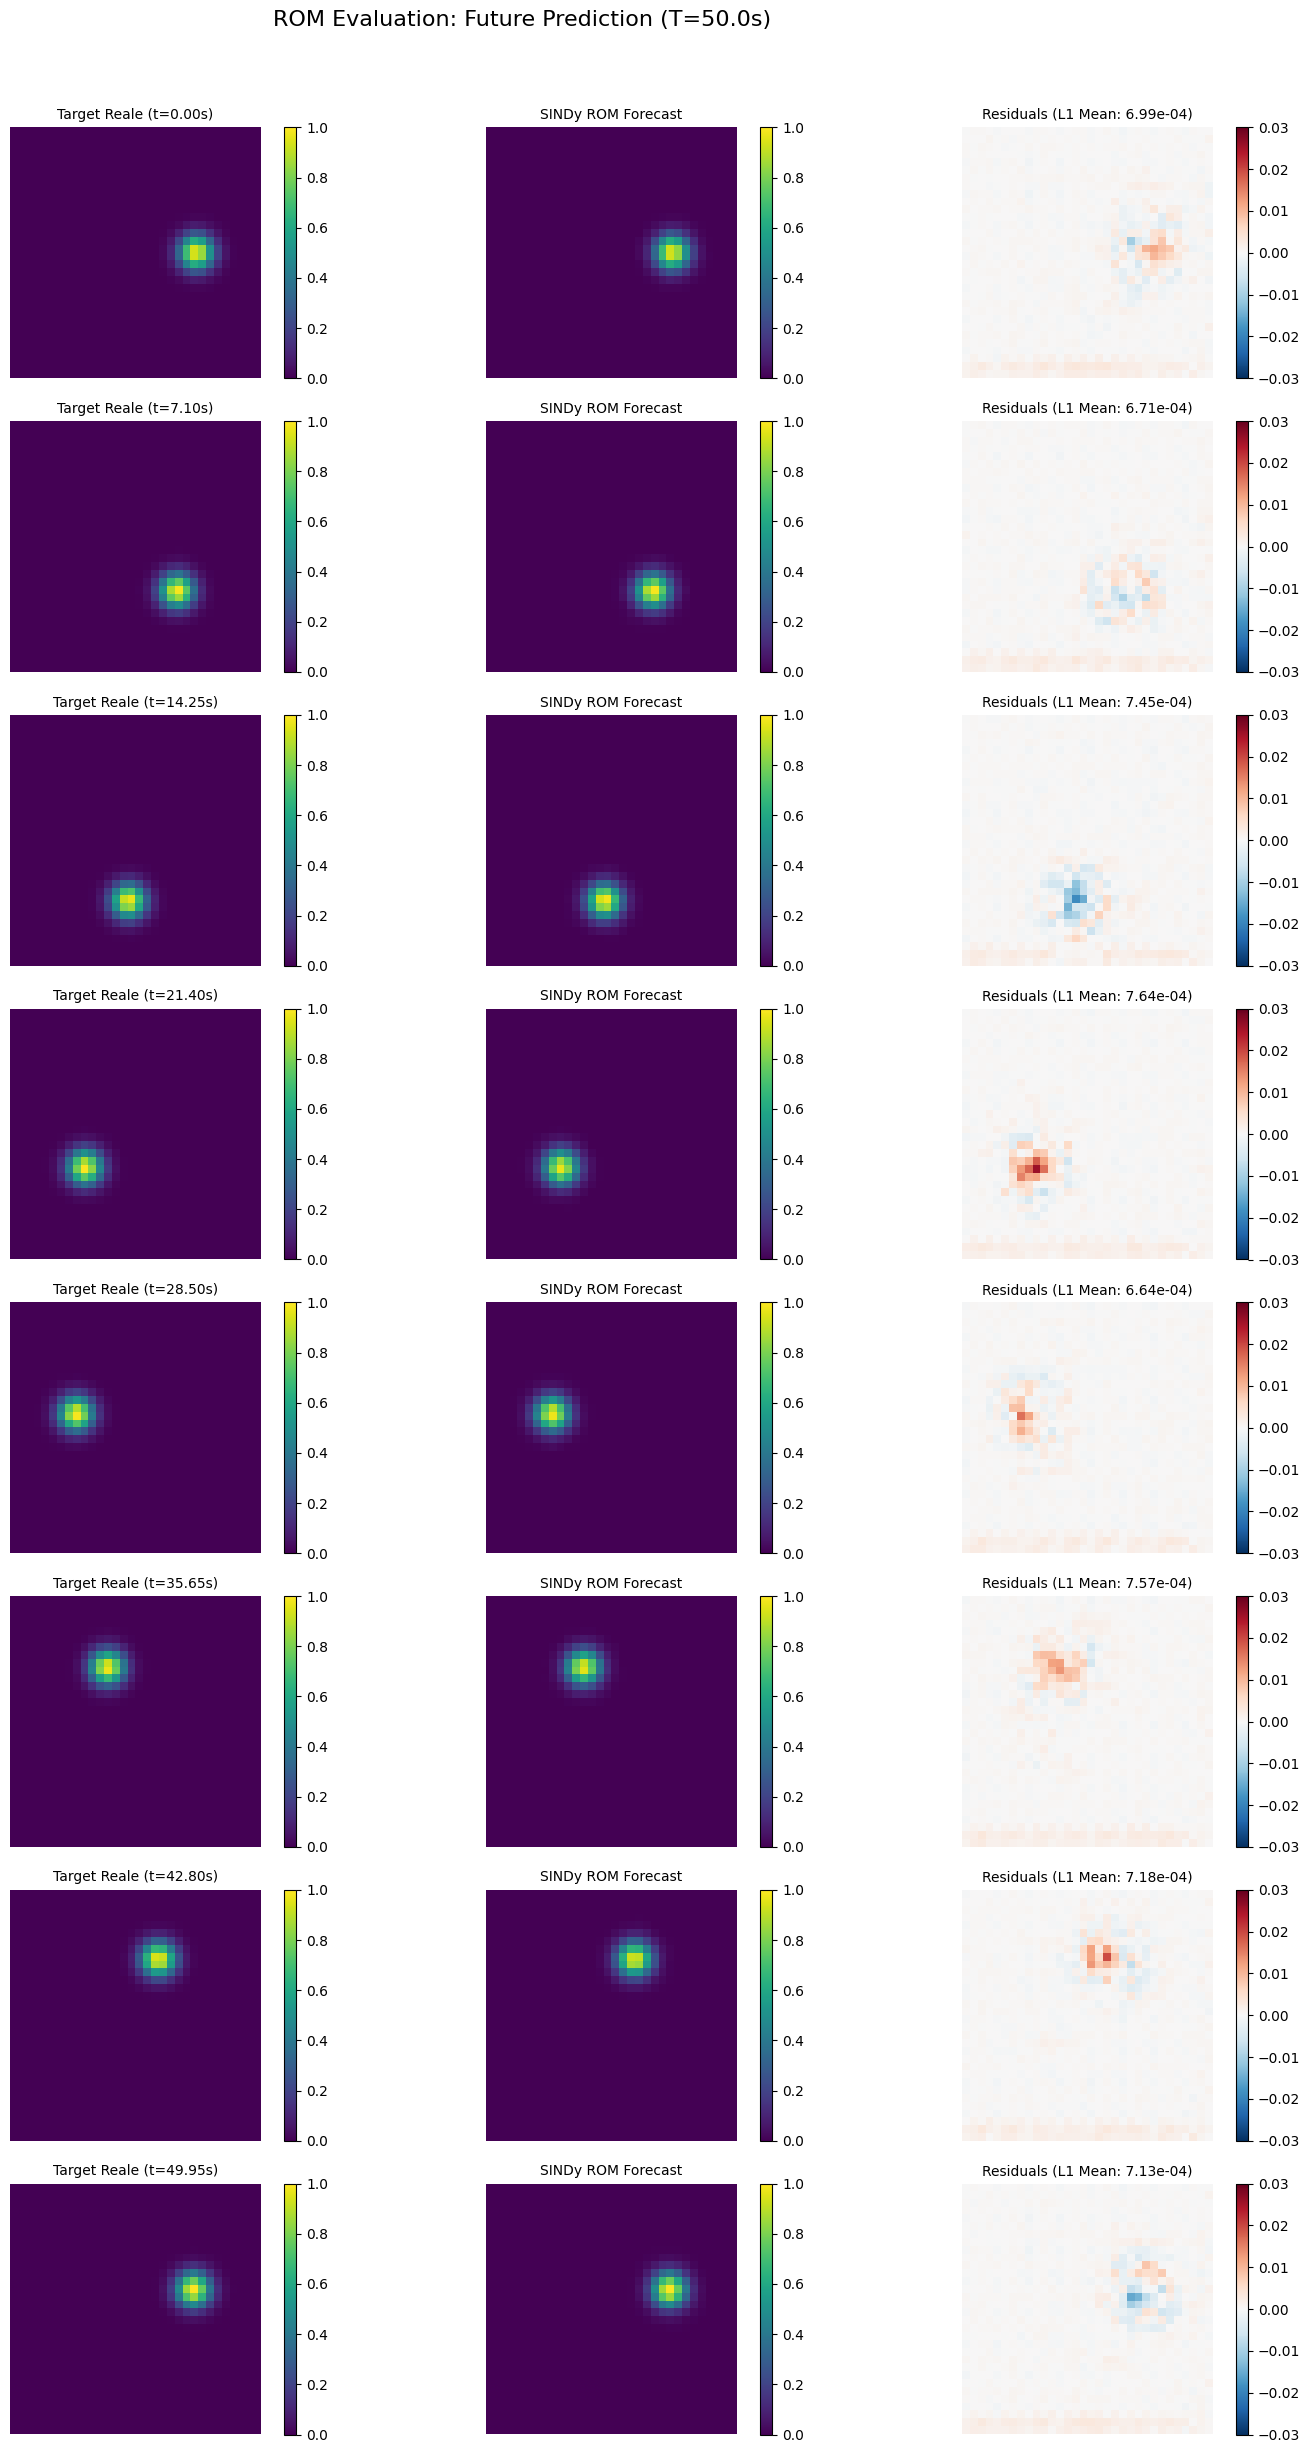

In [12]:
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

def visualize_rom_from_scratch(model, n_test_samples=1000, img_size=32, dt=0.05, num_frames_to_show=8):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    # --- 1. GENERAZIONE DATI DI TEST ---
    t_test = np.arange(n_test_samples) * dt
    z1_test = 0.5 * np.cos(t_test)
    z2_test = 0.5 * np.sin(t_test)
    
    x_grid = np.linspace(-1, 1, img_size)
    y_grid = np.linspace(-1, 1, img_size)
    X_mesh, Y_mesh = np.meshgrid(x_grid, y_grid)
    sigma = 0.1
    
    diff_x = X_mesh[None, :, :] - z1_test[:, None, None]
    diff_y = Y_mesh[None, :, :] - z2_test[:, None, None]
    dist_sq = diff_x**2 + diff_y**2
    img_stack = np.exp(-dist_sq / (2 * sigma**2))
    
    test_x = torch.FloatTensor(img_stack).unsqueeze(-1)
    temp_loader = DataLoader(TensorDataset(test_x), batch_size=32, shuffle=False)

    # --- 2. PROIEZIONE NEL LATENTE ---
    all_z_real = []
    with torch.no_grad():
        for batch in temp_loader:
            z_batch = model.encode(batch[0].to(device))
            all_z_real.append(z_batch.cpu().numpy())
    
    all_z_real = np.concatenate(all_z_real, axis=0)
    all_x_real = test_x.numpy() 

    # --- 3. SIMULAZIONE SINDy ---
    def sindy_dynamics_ode(z_vec, t):
        z_tensor = torch.tensor(z_vec.reshape(1, -1), dtype=torch.float32).to(device)
        with torch.no_grad():
            theta = model.construct_sindy_library(z_tensor)
            dzdt = torch.matmul(theta, model.sindy_coeffs * model.sindy_mask)
        return dzdt.cpu().numpy().flatten()

    t_sim = np.arange(n_test_samples) * dt
    z0 = all_z_real[0] 
    z_simulated = odeint(sindy_dynamics_ode, z0, t_sim)
    
    # --- 4. RICOSTRUZIONE ---
    with torch.no_grad():
        z_sim_tensor = torch.tensor(z_simulated, dtype=torch.float32).to(device)
        x_rec = model.decode(z_sim_tensor) 
        x_sim_reconstructed = x_rec.cpu().numpy()

    # --- 5. VISUALIZZAZIONE STILIZZATA CON SCALE FISSE ---
    indices_to_show = np.linspace(0, n_test_samples - 1, num_frames_to_show, dtype=int)

    fig = plt.figure(figsize=(16, 3 * num_frames_to_show))
    fig.suptitle(f"ROM Evaluation: Future Prediction (T={n_test_samples*dt:.1f}s)", fontsize=16, y=1.02)

    for i, idx in enumerate(indices_to_show):
        img_real = all_x_real[idx].squeeze()
        img_sim = x_sim_reconstructed[idx].squeeze()
        error_map = img_real - img_sim 

        # Subplot 1: Target Reale (Scale: 0 a 1)
        ax1 = plt.subplot(num_frames_to_show, 3, i*3 + 1)
        im1 = ax1.imshow(img_real, cmap='viridis', vmin=0, vmax=1)
        ax1.set_title(f"Target Reale (t={idx*dt:.2f}s)", fontsize=10)
        ax1.axis('off')
        plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

        # Subplot 2: SINDy ROM Forecast (Scale: 0 a 1)
        ax2 = plt.subplot(num_frames_to_show, 3, i*3 + 2)
        im2 = ax2.imshow(img_sim, cmap='viridis', vmin=0, vmax=1)
        ax2.set_title(f"SINDy ROM Forecast", fontsize=10)
        ax2.axis('off')
        plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

        # Subplot 3: Residuals (Scale: -0.03 a 0.03)
        ax3 = plt.subplot(num_frames_to_show, 3, i*3 + 3)
        im3 = ax3.imshow(error_map, cmap='RdBu_r', vmin=-0.03, vmax=0.03)
        ax3.set_title(f"Residuals (L1 Mean: {np.abs(error_map).mean():.2e})", fontsize=10)
        ax3.axis('off')
        plt.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
    
    plt.tight_layout()
    plt.show()

# Esecuzione
visualize_rom_from_scratch(model, n_test_samples=1000, dt=0.05, num_frames_to_show=8)